### **Short Time Fourier Transform (STFT)**

___

In [1]:
%load_ext autoreload
%autoreload 2
import sys, os
import time
import numpy as np 
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath(".."))
from dsp.similarity import cosine_similarity
from dsp.signal_generator import make_time, create_sin

ST1 (โค้ด + สังเกต) Spectral leakage และ Hann window
  - **ทำ:**
    - สร้าง notebook ใหม่ `notebooks/06_STFT.ipynb`
    - `sr = 1000` สร้าง `t` 1 วินาที → `N` ได้ 1000
    - `x1 = create_sin(1, 100, t)` และ `x2 = create_sin(1, 100.5, t)`
    - คำนวณ `mag` แบบ F3 (`np.abs(np.fft.fft(x)) * 2 / N`) ของทั้งสองตัว เก็บเฉพาะครึ่งแรก
    - print ค่าสูงสุดของ `mag` แต่ละตัว
    - นับจำนวน bin ที่ `mag > 0.01` ของแต่ละตัว → print
    - `w = np.hanning(N)` → ทำซ้ำกับ `x1 * w` และ `x2 * w` (print ค่าสูงสุด และจำนวน bin > 0.01)
    - พล็อต stem ช่วง 80–120 Hz ของ `x2` แบบไม่มี window กับมี window ด้วย `plt.subplots(2, 1)`
  - **เครื่องมือใหม่:**
    - `np.hanning(5)` → `[0, 0.5, 1, 0.5, 0]` หน้าต่างที่ค่อย ๆ ขึ้นจาก 0 แล้วลงกลับไป 0
    - นับจำนวนที่เข้าเงื่อนไข: `np.sum(np.array([0.5, 0.001, 0.2]) > 0.01)` → 2
  - **ตอบ:**
    1. ค่าสูงสุดของ `mag` ที่ 100 Hz กับ 100.5 Hz (ไม่มี window) ได้เท่าไร
    > ค่าสูงสุดของ mag ที่ความถี่ 100 Hz กับ 100.5 Hz กรณีที่ไม่มี window มีค่าเท่ากับ 1.0 และประมาณ 0.64 ตามลำดับ
    2. `x2` มี bin ที่ > 0.01 กี่ bin ตอนไม่มี window และตอนมี window
    > ที่สัญญาณ x2 มี bin หรือช่องเก็บข้อมูลความถี่\
    > ในกรณีที่ไม่มี window มีจำนวน 68 ช่องสัญญาณและกรณีมี window 6 ช่องสัญญาณ
    3. หลังคูณ Hann ยอดของ `x1` เหลือเท่าไร
    > หลังคูณ Hann ยอดของสัญญาณ x1 เหลือ 0.5
  - **ใบ้:** 100.5 Hz ไม่ตรงกับ bin ไหนเลย (bin ห่างกัน 1 Hz) พลังงานจึง "รั่ว" ไป bin ข้าง ๆ
  - **เสร็จเมื่อ:** ไม่มี window: ยอด 1.0 กับ ≈0.64, จำนวน bin 1 กับ 68 / มี window: `x2` เหลือ 6 bin, ยอด `x1` ≈0.5 / มีกราฟ 2 รูป และตอบครบ 3 ข้อ

In [2]:
sr = 1000
t = make_time(0, 1, sr)
N = len(t)
x1 = create_sin(1, 100, t)
x2 = create_sin(1, 100.5, t)

freqs = np.arange(N) * (sr/N)   # Arrange the hold frequency with Sampling Rate / N Sample
keep = freqs < sr/2 # Select only first half using Nyquist Frequency.

# Take all signal with FFT.
X1 = np.fft.fft(x1) 
X2 = np.fft.fft(x2)

# Choose only first half of signal after FFT.
mag1 = np.abs(X1[keep])*(2/N)   
mag2 = np.abs(X2[keep])*(2/N)

print(f"Maximum magnitude of signal x1 : {round(np.max(mag1), 2)}")
print(f"Maximum magnitude of signal x2 : {round(np.max(mag2), 2)}")

# Show the number of each mag > 0.01
print(f"The number of mag1 > 0.01 : {len(mag1[mag1>0.01])}")
print(f"The number of mag2 > 0.01 : {len(mag2[mag2>0.01])}")

Maximum magnitude of signal x1 : 1.0
Maximum magnitude of signal x2 : 0.64
The number of mag1 > 0.01 : 1
The number of mag2 > 0.01 : 68


In [3]:
# Have a window function (Hann Window)
w = np.hanning(N)

# Multiply by Hann Window to squeeze at the beginning and the end of signal.
hann_x1 = w*x1
hann_x2 = w*x2

hann_X1 = np.fft.fft(hann_x1)
hann_X2 = np.fft.fft(hann_x2)

hann_mag1 = np.abs(hann_X1[keep])*(2/N)
hann_mag2 = np.abs(hann_X2[keep])*(2/N)

print(f"Maximum magnitude with Hann window of signal x1 : {round(np.max(hann_mag1), 2)}")
print(f"Maximum magnitude with Hann window of signal x2 : {round(np.max(hann_mag2), 2)}")

# Show the number of each mag > 0.01
print(f"The number of mag1 with Hann window > 0.01 : {len(hann_mag1[hann_mag1>0.01])}")
print(f"The number of mag2 with Hann window > 0.01 : {len(hann_mag2[hann_mag2>0.01])}")

Maximum magnitude with Hann window of signal x1 : 0.5
Maximum magnitude with Hann window of signal x2 : 0.42
The number of mag1 with Hann window > 0.01 : 3
The number of mag2 with Hann window > 0.01 : 6


<StemContainer object of 3 artists>

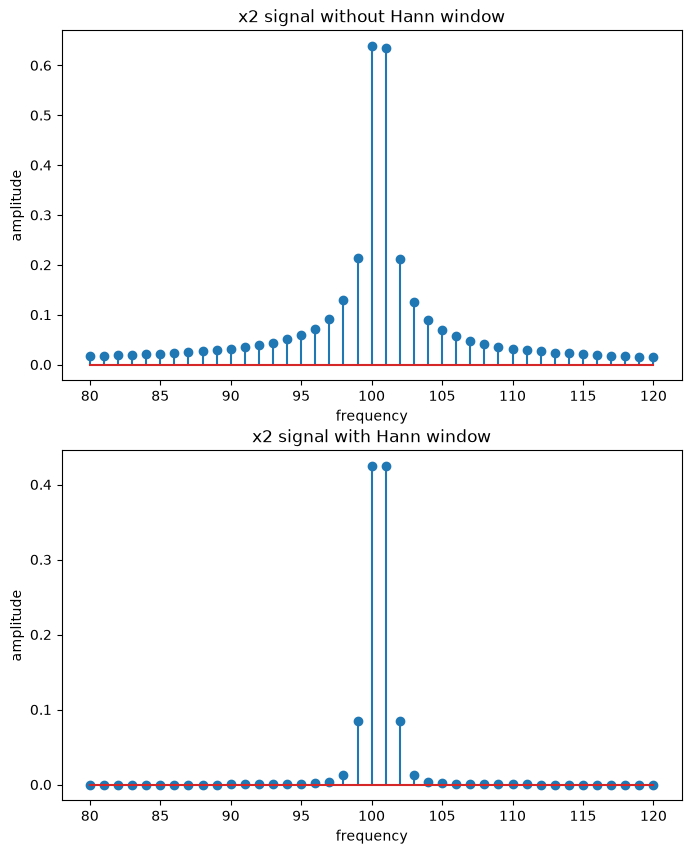

In [ ]:
# Plot stem between 80-120 Hz with Hann window and without Hann window

# subplots(2,1) is create graph in the same image but separate into 2 rows.
fig, (ax1, ax2) = plt.subplots(2,1, figsize=(8, 10)) 

ax1.set(xlabel="frequency", ylabel="amplitude", title="x2 signal without Hann window")


# Note: remind myself -> "Objective of plot this graph is using frequency and amplitude (magnitude) to plot frequency spectrum."
# You have to using magnitude in y-axis not FFT of the signal. 

ax1.stem(freqs[80:121], mag2[80:121])

ax2.set(xlabel="frequency", ylabel="amplitude", title="x2 signal with Hann window")
ax2.stem(freqs[80:121], hann_mag2[80:121])